In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid activation and its derivative
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1.0 - x)

# XOR input and target outputs
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([[0], [1], [1], [0]])

class TwoLayerNN:
    def __init__(self, input_dim=2, hidden_dim=4, output_dim=1, seed=42):
        np.random.seed(seed)
        # Initialize weights and biases randomly
        self.W1 = np.random.uniform(-1, 1, (input_dim, hidden_dim))
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.uniform(-1, 1, (hidden_dim, output_dim))
        self.b2 = np.zeros((1, output_dim))

    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, lr):
        # Backpropagation of error
        error_out = y - output
        delta_out = error_out * sigmoid_derivative(output)

        error_hidden = delta_out.dot(self.W2.T)
        delta_hidden = error_hidden * sigmoid_derivative(self.a1)

        # Gradient descent weight updates
        self.W2 += self.a1.T.dot(delta_out) * lr
        self.b2 += np.sum(delta_out, axis=0, keepdims=True) * lr
        self.W1 += X.T.dot(delta_hidden) * lr
        self.b1 += np.sum(delta_hidden, axis=0, keepdims=True) * lr

    def train(self, X, y, lr=0.1, epochs=10000):
        loss_history = []
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(X, y, output, lr)
            # Mean Squared Error Loss
            loss = np.mean((y - output) ** 2)
            loss_history.append(loss)
        return loss_history

Predictions with LR 0.01:
[0.479 0.521 0.484 0.517]
Predictions with LR 0.1:
[0.053 0.922 0.924 0.094]
Predictions with LR 0.5:
[0.015 0.976 0.977 0.029]
Predictions with LR 1.0:
[0.009 0.984 0.985 0.019]
Predictions with LR 5.0:
[0.005 0.995 0.993 0.007]


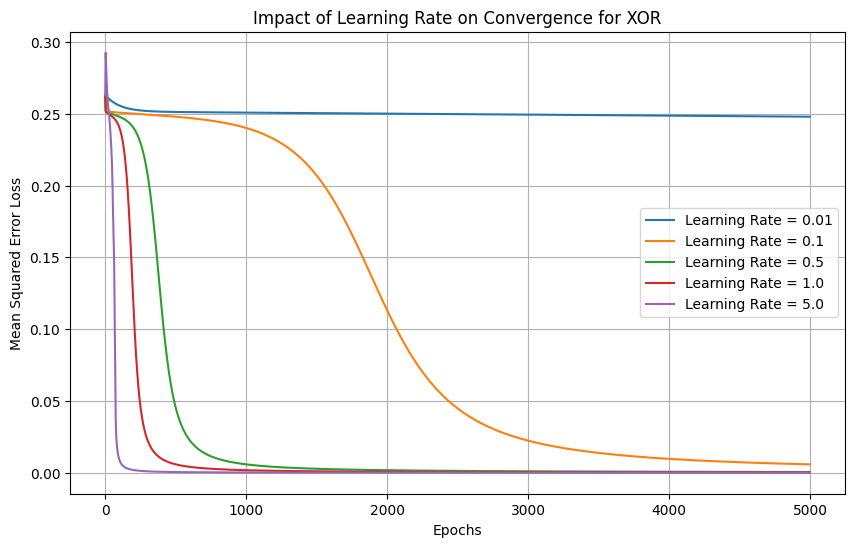

In [11]:
learning_rates = [0.01, 0.1, 0.5, 1.0, 5.0]
epochs = 5000
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    nn = TwoLayerNN(input_dim=2, hidden_dim=4, output_dim=1, seed=42)
    loss_history = nn.train(X_xor, y_xor, lr=lr, epochs=epochs)
    plt.plot(loss_history, label=f'Learning Rate = {lr}')

    # Display predictions at the end of training for this LR
    final_predictions = nn.forward(X_xor)
    print(f"Predictions with LR {lr}:\n{final_predictions.flatten().round(3)}")

plt.title('Impact of Learning Rate on Convergence for XOR')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error Loss')
plt.legend()
plt.grid(True)
plt.show()

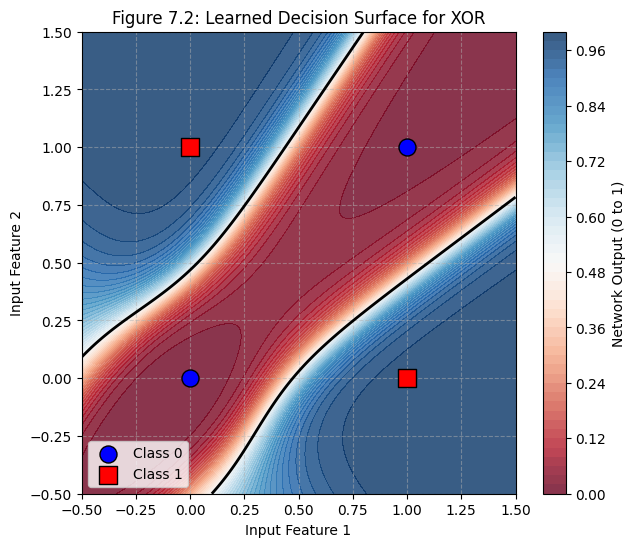

In [12]:
def plot_decision_boundary(nn, X, y, title):
    # Create a grid of points spanning [-0.5, 1.5]
    x_min, x_max = -0.5, 1.5
    y_min, y_max = -0.5, 1.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

    # Flatten the grid and make predictions
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    preds = nn.forward(grid_points)
    zz = preds.reshape(xx.shape)

    # Plot decision boundary (Figure 7.2)
    plt.figure(figsize=(7, 6))
    contour = plt.contourf(xx, yy, zz, levels=50, cmap='RdBu', alpha=0.8)
    plt.colorbar(contour, label='Network Output (0 to 1)')

    # Draw 0.5 boundary contour line in black
    plt.contour(xx, yy, zz, levels=[0.5], colors='black', linewidths=2)

    # Plot training points: Circles for class 0, Squares for class 1
    for i in range(len(X)):
        marker = 'o' if y[i, 0] == 0 else 's'
        color = 'blue' if y[i, 0] == 0 else 'red'
        plt.scatter(X[i, 0], X[i, 1], marker=marker, color=color, s=150, edgecolors='k', zorder=5, label=f'Class {y[i, 0]}' if f'Class {y[i, 0]}' not in plt.gca().get_legend_handles_labels()[1] else "")

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title(title)
    plt.xlabel('Input Feature 1')
    plt.ylabel('Input Feature 2')
    plt.legend(loc='lower left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# Train a model with learning rate 1.0 to ensure solid convergence for the plot
optimal_nn = TwoLayerNN(input_dim=2, hidden_dim=4, output_dim=1, seed=42)
_ = optimal_nn.train(X_xor, y_xor, lr=1.0, epochs=10000)

# Plot the resulting decision surface
plot_decision_boundary(optimal_nn, X_xor, y_xor, 'Figure 7.2: Learned Decision Surface for XOR')